In [1]:
import pandas as pd
df=pd.read_csv("/content/credit_risk_dataset.csv")
df.head(4)

FileNotFoundError: [Errno 2] No such file or directory: '/content/credit_risk_dataset.csv'


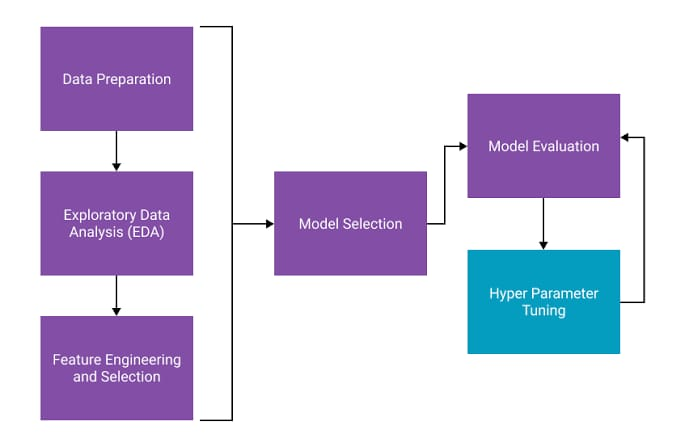

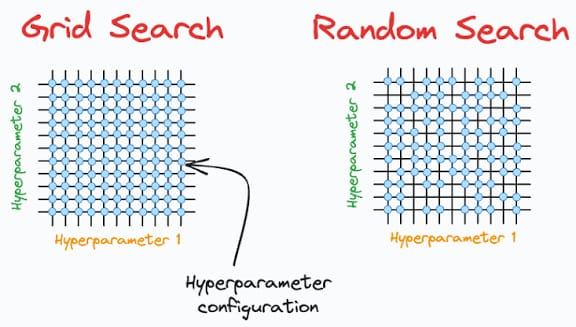

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [ ]:
df['person_emp_length']=df['person_emp_length'].fillna(df['person_emp_length'].mean())
df['loan_int_rate']=df['loan_int_rate'].fillna(df['loan_int_rate'].mean())


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.085333,6322.086646,3.081605,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,11.011695,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
df.shape

(32581, 12)

In [ ]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


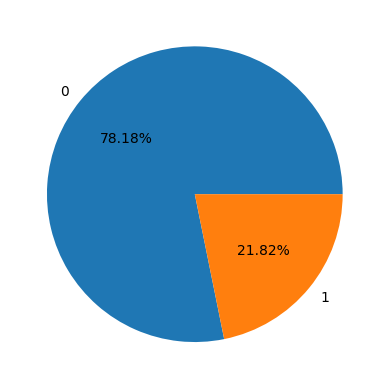

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.pie(df['loan_status'].value_counts(),labels=df['loan_status'].value_counts().index,autopct='%1.2f%%')
plt.show()

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [ ]:
from scipy.stats import chi2_contingency
table = pd.crosstab(df['loan_intent'], df['loan_status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')


loan_status           0     1
loan_intent                  
DEBTCONSOLIDATION  3722  1490
EDUCATION          5342  1111
HOMEIMPROVEMENT    2664   941
MEDICAL            4450  1621
PERSONAL           4423  1098
VENTURE            4872   847
Chi2: 520.51, p-value: 0.0000, Degrees of freedom: 5


In [ ]:
from scipy.stats import chi2_contingency
table = pd.crosstab(df['loan_grade'], df['loan_status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

loan_status     0     1
loan_grade             
A            9704  1073
B            8750  1701
C            5119  1339
D            1485  2141
E             343   621
F              71   170
G               1    63
Chi2: 5609.18, p-value: 0.0000, Degrees of freedom: 6


In [ ]:
from scipy.stats import chi2_contingency
table = pd.crosstab(df['person_home_ownership'], df['loan_status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

loan_status                0     1
person_home_ownership             
MORTGAGE               11754  1690
OTHER                     74    33
OWN                     2391   193
RENT                   11254  5192
Chi2: 1907.98, p-value: 0.0000, Degrees of freedom: 3


In [ ]:
from scipy.stats import chi2_contingency
table = pd.crosstab(df['cb_person_default_on_file'], df['loan_status'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

loan_status                    0     1
cb_person_default_on_file             
N                          21900  4936
Y                           3573  2172
Chi2: 1044.44, p-value: 0.0000, Degrees of freedom: 1


In [ ]:
import numpy as np
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_cred_hist_length']

In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'person_age ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df        sum_sq     mean_sq          F    PR(>F)
C(loan_status)      1.0  6.142184e+02  614.218402  15.248536  0.000094
Residual        32579.0  1.312298e+06   40.280483        NaN       NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'person_income ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df        sum_sq       mean_sq          F         PR(>F)
C(loan_status)      1.0  2.611740e+12  2.611740e+12  694.26853  2.044208e-151
Residual        32579.0  1.225576e+14  3.761859e+09        NaN            NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'person_emp_length ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df         sum_sq      mean_sq           F        PR(>F)
C(loan_status)      1.0    3565.577471  3565.577471  215.039757  1.560459e-48
Residual        32579.0  540192.892011    16.581015         NaN           NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'loan_amnt ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df        sum_sq       mean_sq          F        PR(>F)
C(loan_status)      1.0  1.445948e+10  1.445948e+10  365.82038  4.239733e-81
Residual        32579.0  1.287723e+12  3.952618e+07        NaN           NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'loan_int_rate ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df         sum_sq       mean_sq            F  PR(>F)
C(loan_status)      1.0   31551.265930  31551.265930  3699.672523     0.0
Residual        32579.0  277837.750827      8.528124          NaN     NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'loan_percent_income ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df      sum_sq    mean_sq            F  PR(>F)
C(loan_status)      1.0   53.464201  53.464201  5476.974676     0.0
Residual        32579.0  318.024150   0.009762          NaN     NaN


In [ ]:
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'cb_person_cred_hist_length ~ C(loan_status)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df         sum_sq     mean_sq         F    PR(>F)
C(loan_status)      1.0     129.194555  129.194555  7.858753  0.005061
Residual        32579.0  535584.867690   16.439574       NaN       NaN


In [ ]:
df=df.drop('loan_int_rate',axis=1)


KeyError: "['loan_int_rate'] not found in axis"

In [ ]:
df=df.drop('loan_percent_income',axis=1)

In [ ]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_status,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,1,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,0,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,1,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,1,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,1,Y,4
...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,0,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,0,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,1,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,0,N,26


In [ ]:
from imblearn.under_sampling import RandomUnderSampler
x=df.drop('loan_status',axis=1)
y=df['loan_status']
smote=RandomUnderSampler()
x_smote,y_smote=smote.fit_resample(x,y)
x_smote.shape,y_smote.shape

((14216, 9), (14216,))

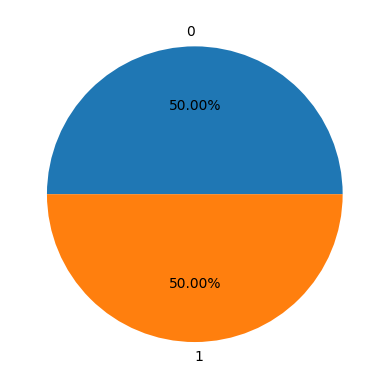

In [ ]:
plt.pie(y_smote.value_counts(),labels=y_smote.value_counts().index,autopct='%1.2f%%')
plt.show()

In [ ]:
cat_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
for col in cat_cols:
  encoder=OrdinalEncoder()
  x_smote[col]=encoder.fit_transform(x_smote[[col]])
x_smote

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,cb_person_default_on_file,cb_person_cred_hist_length
21664,27,50000,0.0,4.0,1.0,1.0,2100,0.0,6
9451,24,81600,3.0,5.0,5.0,2.0,8000,1.0,2
28067,27,67000,3.0,5.0,0.0,2.0,12000,1.0,9
4949,25,42996,2.0,1.0,5.0,3.0,7200,0.0,4
10268,25,71000,3.0,5.0,2.0,0.0,9600,0.0,4
...,...,...,...,...,...,...,...,...,...
32563,52,71520,3.0,0.0,1.0,4.0,7000,1.0,24
32565,57,40000,3.0,1.0,3.0,0.0,15000,0.0,21
32571,60,45600,3.0,1.0,5.0,1.0,20000,0.0,26
32574,52,65004,3.0,4.0,4.0,3.0,20000,1.0,19


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x=scaler.fit_transform(x_smote)
x


array([[-0.09989935, -0.20241884, -1.33831534, ..., -1.19628559,
        -0.53668535,  0.06133759],
       [-0.57979431,  0.46434807,  0.79594307, ..., -0.30821371,
         1.86328916, -0.92645648],
       [-0.09989935,  0.15628488,  0.79594307, ...,  0.29386893,
         1.86328916,  0.80218315],
       ...,
       [ 5.17894521, -0.2952598 ,  0.79594307, ...,  1.49803419,
        -0.53668535,  5.00030798],
       [ 3.89922532,  0.11416884,  0.79594307, ...,  1.49803419,
         1.86328916,  3.27166835],
       [ 5.97877014,  0.34618685,  0.79594307, ...,  3.75584406,
        -0.53668535,  5.49420502]])

In [ ]:
from sklearn.model_selection import train_test_split
x_smotetrain,x_smotetest,y_smotetrain,y_smotetest=train_test_split(x_smote,y_smote,test_size=0.2,random_state=42)
from sklearn.ensemble import RandomForestClassifier
model= RandomForestClassifier()
model.fit(x_smotetrain,y_smotetrain)

y_pred=model.predict(x_smotetrain)


In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report  #r2_score
accuracy_score(y_smotetrain,y_pred)
confusion_matrix(y_smotetrain,y_pred)
print(classification_report(y_smotetrain,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5656
           1       1.00      1.00      1.00      5716

    accuracy                           1.00     11372
   macro avg       1.00      1.00      1.00     11372
weighted avg       1.00      1.00      1.00     11372



In [ ]:
model= RandomForestClassifier()
model.fit(x_smotetrain,y_smotetrain)
y_pred=model.predict(x_smotetest)


In [ ]:
accuracy_score(y_smotetest,y_pred)
confusion_matrix(y_smotetest,y_pred)
print(classification_report(y_smotetest,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1452
           1       0.89      0.80      0.84      1392

    accuracy                           0.85      2844
   macro avg       0.86      0.85      0.85      2844
weighted avg       0.86      0.85      0.85      2844



In [ ]:


rf_param={
    'n_estimators':[10,20,30,40,50,60,70,80,90,100],
    'max_depth':[1,2,3,4,5,6,7,8,9,10],                  #[],(),{}
    'min_samples_split':[2,3,4,5,6,7,8,9,10],
    'min_samples_leaf':[1,2,3,4,5,6,7,8,9,10]
}
from sklearn.model_selection import RandomizedSearchCV
rf_model=RandomForestClassifier()
rf_cv=RandomizedSearchCV(rf_model,rf_param,cv=5)
rf_cv.fit(x_smotetrain,y_smotetrain)
rf_cv.best_params_


{'n_estimators': 100,
 'min_samples_split': 4,
 'min_samples_leaf': 1,
 'max_depth': 1}

In [ ]:
rf_param={
    'n_estimators':[10,20,30,40,50,60,70,80,90,100],
    'max_depth':[1,2,3,4,5,6,7,8,9,10],                  #[],(),{}
    'min_samples_split':[2,3,4,5,6,7,8,9,10],
    'min_samples_leaf':[1,2,3,4,5,6,7,8,9,10]
}
from sklearn.model_selection import RandomizedSearchCV
rf_model=RandomForestClassifier()
rf_cv=RandomizedSearchCV(rf_model,rf_param,cv=5)           #Dataset split into 5 parts   #
                                                           #Model trains on 4 parts, validates on 1, repeat 5 times


rf_cv.fit(x_smotetest,y_smotetest)
rf_cv.best_params_


{'n_estimators': 10,
 'min_samples_split': 5,
 'min_samples_leaf': 4,
 'max_depth': 5}

In [ ]:

rf_model=RandomForestClassifier(n_estimators=100,min_samples_split=4,min_samples_leaf=1,max_depth=1)
model=rf_model.fit(x_smotetrain,y_smotetrain)
y_pred=model.predict(x_smotetrain)
accuracy_score(y_smotetrain,y_pred)
confusion_matrix(y_smotetrain,y_pred)
print(classification_report(y_smotetrain,y_pred))

              precision    recall  f1-score   support

           0       0.54      0.95      0.69      1169
           1       0.82      0.20      0.32      1183

    accuracy                           0.57      2352
   macro avg       0.68      0.58      0.50      2352
weighted avg       0.68      0.57      0.50      2352



In [ ]:
rf_model=RandomForestClassifier(n_estimators=10,min_samples_split=5,min_samples_leaf=4,max_depth=5)
model=rf_model.fit(x_smotetrain,y_smotetrain)
y_pred=model.predict(x_smotetest)
accuracy_score(y_smotetest,y_pred)
confusion_matrix(y_smotetest,y_pred)
print(classification_report(y_smotetest,y_pred))

              precision    recall  f1-score   support

           0       0.56      0.81      0.66       301
           1       0.62      0.32      0.42       287

    accuracy                           0.57       588
   macro avg       0.59      0.57      0.54       588
weighted avg       0.59      0.57      0.54       588



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(x_smotetrain,y_smotetrain)
y_pred=knn.predict(x_smotetrain)
accuracy_score(y_smotetrain,y_pred)
confusion_matrix(y_smotetrain,y_pred)
print(classification_report(y_smotetrain,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.83      0.82      5656
           1       0.83      0.81      0.82      5716

    accuracy                           0.82     11372
   macro avg       0.82      0.82      0.82     11372
weighted avg       0.82      0.82      0.82     11372



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(x_smotetrain,y_smotetrain)
y_pred=knn.predict(x_smotetest)
accuracy_score(y_smotetest,y_pred)
confusion_matrix(y_smotetest,y_pred)
print(classification_report(y_smotetest,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1452
           1       0.74      0.73      0.74      1392

    accuracy                           0.74      2844
   macro avg       0.74      0.74      0.74      2844
weighted avg       0.74      0.74      0.74      2844



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=3)
knn.fit(x_smotetrain,y_smotetrain)
y_pred=knn.predict(x_smotetrain)
accuracy_score(y_smotetrain,y_pred)
confusion_matrix(y_smotetrain,y_pred)
print(classification_report(y_smotetrain,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      5656
           1       0.86      0.86      0.86      5716

    accuracy                           0.86     11372
   macro avg       0.86      0.86      0.86     11372
weighted avg       0.86      0.86      0.86     11372



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=7)
knn.fit(x_smotetrain,y_smotetrain)
y_pred=knn.predict(x_smotetest)
accuracy_score(y_smotetest,y_pred)
confusion_matrix(y_smotetest,y_pred)
print(classification_report(y_smotetest,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.77      0.75      1452
           1       0.75      0.71      0.73      1392

    accuracy                           0.74      2844
   macro avg       0.74      0.74      0.74      2844
weighted avg       0.74      0.74      0.74      2844



In [ ]:
from sklearn.model_selection import KFold,cross_val_score
kfold=KFold(n_splits=5)
knn=KNeighborsClassifier()
cross_val_score(knn,x,y_smote,cv=kfold)
print(cross_val_score(knn,x,y_smote,cv=kfold))
print(cross_val_score(knn,x,y_smote,cv=kfold).mean())

[0.66279887 0.65247977 0.74463595 0.38937742 0.1206472 ]
0.5139878439060975


In [ ]:
for train_index,test_index in kfold.split(x):
  x_train,x_test=x[train_index],x[test_index]
  y_train,y_test=y_smote.iloc[train_index],y_smote.iloc[test_index]
  knn.fit(x_train,y_train)
  y_pred=knn.predict(x_test)
  print("Fold Accuracy:", accuracy_score(y_test,y_pred))
  print(confusion_matrix(y_test,y_pred))
  print(classification_report(y_test,y_pred))
  print("-"*50)

Fold Accuracy: 0.6627988748241913
[[1885  959]
 [   0    0]]
              precision    recall  f1-score   support

           0       1.00      0.66      0.80      2844
           1       0.00      0.00      0.00         0

    accuracy                           0.66      2844
   macro avg       0.50      0.33      0.40      2844
weighted avg       1.00      0.66      0.80      2844

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold Accuracy: 0.6524797748856841
[[1855  988]
 [   0    0]]
              precision    recall  f1-score   support

           0       1.00      0.65      0.79      2843
           1       0.00      0.00      0.00         0

    accuracy                           0.65      2843
   macro avg       0.50      0.33      0.39      2843
weighted avg       1.00      0.65      0.79      2843

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold Accuracy: 0.7446359479423145
[[1105  316]
 [ 410 1012]]
              precision    recall  f1-score   support

           0       0.73      0.78      0.75      1421
           1       0.76      0.71      0.74      1422

    accuracy                           0.74      2843
   macro avg       0.75      0.74      0.74      2843
weighted avg       0.75      0.74      0.74      2843

--------------------------------------------------
Fold Accuracy: 0.38937741822018995
[[   0    0]
 [1736 1107]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.39      0.56      2843

    accuracy                           0.39      2843
   macro avg       0.50      0.19      0.28      2843
weighted avg       1.00      0.39      0.56      2843

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold Accuracy: 0.12064720365810763
[[   0    0]
 [2500  343]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       1.00      0.12      0.22      2843

    accuracy                           0.12      2843
   macro avg       0.50      0.06      0.11      2843
weighted avg       1.00      0.12      0.22      2843

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
for train_index,test_index in kfold.split(x):
  x_train,x_test=x[train_index],x[test_index]
  y_train,y_test=y[train_index],y[test_index]
  knn.fit(x_test,y_test)
  y_pred=knn.predict(x_test)
  print(accuracy_score(y_test,y_pred))
  print(confusion_matrix(y_test,y_pred))
  print(classification_report(y_test,y_pred))

0.784
[[320  33]
 [ 75  72]]
              precision    recall  f1-score   support

           0       0.81      0.91      0.86       353
           1       0.69      0.49      0.57       147

    accuracy                           0.78       500
   macro avg       0.75      0.70      0.71       500
weighted avg       0.77      0.78      0.77       500

0.794
[[338  22]
 [ 81  59]]
              precision    recall  f1-score   support

           0       0.81      0.94      0.87       360
           1       0.73      0.42      0.53       140

    accuracy                           0.79       500
   macro avg       0.77      0.68      0.70       500
weighted avg       0.78      0.79      0.77       500

0.756
[[315  37]
 [ 85  63]]
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       352
           1       0.63      0.43      0.51       148

    accuracy                           0.76       500
   macro avg       0.71      0.66      0.

In [ ]:
model=KNeighborsClassifier(n_neighbors=10)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.96      0.82       340
           1       0.67      0.19      0.30       160

    accuracy                           0.71       500
   macro avg       0.69      0.57      0.56       500
weighted avg       0.70      0.71      0.65       500



In [ ]:
model=KNeighborsClassifier(n_neighbors=10)
model.fit(x_test,y_test)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.73      0.99      0.84       340
           1       0.92      0.22      0.35       160

    accuracy                           0.74       500
   macro avg       0.83      0.60      0.60       500
weighted avg       0.79      0.74      0.68       500



In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid={
    'n_neighbors':[3,4,5,6,7,8,9,10],
    'weights':['uniform','distance'],
    'metric':['euclidean','manhattan']

}
knn=KNeighborsClassifier()
knn_cv=GridSearchCV(knn,param_grid,cv=5)
knn_cv.fit(x_train,y_train)
knn_cv.best_params_

{'metric': 'manhattan', 'n_neighbors': 10, 'weights': 'uniform'}

In [ ]:
knn=KNeighborsClassifier()
knn_cv=GridSearchCV(knn,param_grid,cv=5)
knn_cv.fit(x_test,y_test)
knn_cv.best_params_

{'metric': 'euclidean', 'n_neighbors': 10, 'weights': 'uniform'}

In [ ]:
model=KNeighborsClassifier(n_neighbors=10,metric='manhattan',weights='uniform')
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.96      0.82       340
           1       0.71      0.20      0.31       160

    accuracy                           0.72       500
   macro avg       0.71      0.58      0.57       500
weighted avg       0.72      0.72      0.66       500



In [ ]:
model=KNeighborsClassifier(n_neighbors=10,metric='euclidean',weights='uniform')
model.fit(x_test,y_test)
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.73      0.99      0.84       340
           1       0.92      0.22      0.35       160

    accuracy                           0.74       500
   macro avg       0.83      0.60      0.60       500
weighted avg       0.79      0.74      0.68       500

